# 05 · De tabla a red neuronal: DQN
**Entornos:** MiniDespacho (diminuto y mediano) · **Tiempo de ejecución:** ≤ 7 min en CPU · **Criterio de la lección:** en "diminuto" el DQN queda a ≤ 10 % del óptimo; en "mediano" llega
al menos a mitad de camino entre el aleatorio y `GreedyDespacho`; y una política aleatoria pisa tantos estados distintos que no cabe en una tabla.

## 1. La idea en una frase
Una tabla guarda un valor por estado; una **red neuronal** guarda una función que *generaliza*: estados parecidos reciben valores parecidos, incluso estados nunca vistos.

**En el sistema de Luca:** el Transformer de 2,24 M de parámetros es esa función; ninguna tabla podría cubrir los estados del PTCG.
**En un problema de negocio:** un despacho con 6 camiones y 12 pedidos pendientes tiene demasiados estados para tabularlos; la red aprende de una fracción y generaliza al resto.

## 2. La intuición y la fórmula
DQN entrena una red $Q_\theta(s,\cdot)$ que da un valor por **id de acción** con la misma idea TD de la lección 4, pero como regresión:

$$\mathcal{L}(\theta) = \text{Huber}\Bigl(Q_\theta(s,a),\; r + \gamma \max_{a' \in \text{legales}(s')} Q_{\bar\theta}(s',a')\Bigr)$$

Dos trucos hacen estable el entrenamiento: un **buffer de repetición** (muestrear transiciones pasadas rompe la correlación entre pasos consecutivos)
y una **red objetivo** $Q_{\bar\theta}$, copia retrasada de la red principal, para que el objetivo no se mueva a cada paso. El máximo se toma solo sobre las acciones **legales** de $s'$.

In [1]:
import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from dataclasses import replace
from rlf.core import EVAL_SEED_BASE, VecEnv, BatchObs, flatten_obs, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, normalized_score_ci, passes_lower
from rlf.eval.arena import evaluate_policy
from rlf.envs.despacho import DespachoConfig, DespachoEnv, build_mdp
from rlf.agents.baselines import RandomPolicy, GreedyDespacho
from rlf.agents.tabular import value_iteration
from rlf.agents.dqn import DQN, DQNConfig
from rlf.nets.mlp import MLP
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
make_small = lambda: DespachoEnv.from_size("diminuto")
make_med = lambda: DespachoEnv.from_size("mediano")

mdp = build_mdp(DespachoConfig.from_size("diminuto"))
V, Q_star, policy_opt = value_iteration(mdp)
v_star = float(mdp.p0 @ V)
print(f"V* (diminuto) = {v_star:.4f}")

V* (diminuto) = -4.2049


## 3. El núcleo: pérdida TD con red objetivo y bucle de repetición
Escrito inline para un solo entorno. Una celda comprueba que el objetivo TD coincide con el de `rlf.agents.dqn.DQN`.

In [2]:
def td_targets(target_net, reward, next_state, done, next_legal_mask, gamma=1.0):
    """r + γ · max sobre acciones LEGALES de Q_objetivo(s'); sin bootstrap si terminó."""
    with torch.no_grad():
        q_next = target_net(next_state).masked_fill(~next_legal_mask, float("-inf")).max(1).values
        return torch.where(done, reward, reward + gamma * q_next)

def train_dqn_inline(env, steps, hidden=(64, 64), lr=1e-3, batch=64, buffer_size=20_000, target_every=500, seed=0):
    """DQN mínimo de un solo entorno: ε-greedy enmascarado + buffer + red objetivo."""
    rng = np.random.default_rng(seed)
    spec = env.spec
    obs_dim = spec.state_dim + spec.max_entities * spec.entity_dim
    torch.manual_seed(seed)
    q_net, tgt = MLP(obs_dim, hidden, spec.n_actions), MLP(obs_dim, hidden, spec.n_actions)
    tgt.load_state_dict(q_net.state_dict())
    opt = torch.optim.Adam(q_net.parameters(), lr=lr)
    S = np.zeros((buffer_size, obs_dim), np.float32); A = np.zeros(buffer_size, np.int64); R = np.zeros(buffer_size, np.float32)
    S2 = np.zeros_like(S); D = np.zeros(buffer_size, bool); M = np.zeros((buffer_size, spec.n_actions), bool)
    n = pos = 0
    def flat(o):
        return flatten_obs(BatchObs.from_obs(o, spec))[0]
    obs, ep_ret, returns = env.reset(seed), 0.0, []
    for t in range(steps):
        eps = max(0.05, 1.0 - t / (0.5 * steps))                       # ε baja de 1 a 0,05 en la mitad
        if rng.random() < eps:
            j = int(rng.integers(obs.n_options))
        else:
            with torch.no_grad():
                q = q_net(torch.from_numpy(flat(obs))[None])[0].numpy()
            j = int(np.argmax(q[obs.option_ids]))                        # mejor Q entre las opciones legales
        st = env.step(j)
        S[pos], A[pos], R[pos], S2[pos], D[pos] = flat(obs), obs.option_ids[j], st.rewards[0], flat(st.obs), st.done
        M[pos] = False; M[pos, st.obs.option_ids] = True
        pos, n = (pos + 1) % buffer_size, min(n + 1, buffer_size)
        ep_ret += st.rewards[0]
        obs = st.obs
        if st.done:
            returns.append(ep_ret); ep_ret = 0.0; obs = env.reset(int(rng.integers(10_000_000)))
        if n >= 500 and t % 4 == 0:                                      # una actualización cada 4 pasos
            idx = rng.integers(0, n, batch)
            s, a, r, s2, d, m = (torch.from_numpy(x[idx]) for x in (S, A, R, S2, D, M))
            q = q_net(s).gather(1, a[:, None]).squeeze(1)
            loss = F.smooth_l1_loss(q, td_targets(tgt, r, s2, d, m))
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(q_net.parameters(), 10.0); opt.step()
        if t % target_every == 0:
            tgt.load_state_dict(q_net.state_dict())                      # copia dura a la red objetivo
    return q_net, returns

# verificación cruzada del objetivo TD contra rlf
ref = DQN(make_small().spec, DQNConfig(), seed=0)
rs = torch.tensor([-1.0, -3.0, 0.0]); s2 = torch.randn(3, ref.obs_dim); dn = torch.tensor([False, False, True])
mk = torch.tensor([[True, True, False], [False, True, True], [True, True, True]])
assert torch.allclose(td_targets(ref.target_net, rs, s2, dn, mk), ref.td_target(rs, s2, dn, mk))
print("objetivo TD inline == rlf")

objetivo TD inline == rlf


## 4. Entrenar y graficar la curva de aprendizaje
Primero el bucle inline (20 000 pasos) para ver que aprende; después el DQN de `rlf` con 8 entornos en paralelo: 80 000 pasos en "diminuto" y 100 000 en "mediano".

bucle inline: retorno medio de los últimos 300 episodios = -4.42  (aleatorio ≈ -14.43)


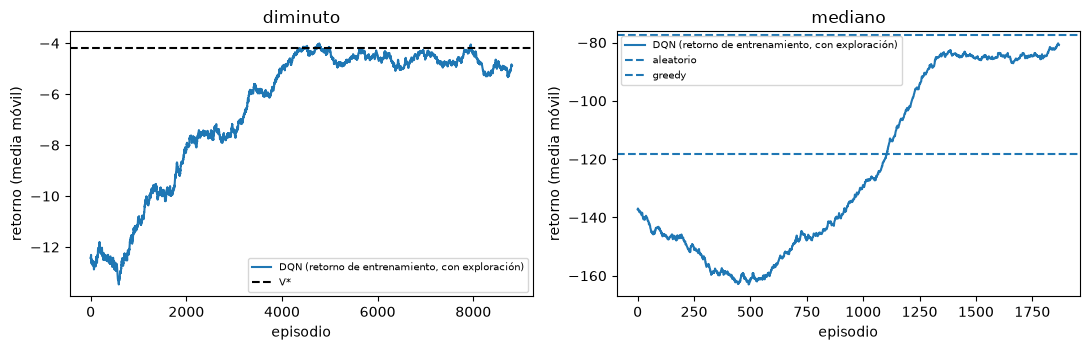

In [3]:
q_inline, ret_inline = train_dqn_inline(make_small(), 20_000, seed=TRAIN_SEED)
print(f"bucle inline: retorno medio de los últimos 300 episodios = {np.mean(ret_inline[-300:]):.2f}  (aleatorio ≈ {evaluate_policy(make_small, RandomPolicy(TRAIN_SEED), 1000).mean():.2f})")

dqn_small = DQN(make_small().spec, DQNConfig(), seed=TRAIN_SEED)
dqn_small.train(VecEnv(make_small, 8, seed=TRAIN_SEED), 80_000)
dqn_med = DQN(make_med().spec, DQNConfig(), seed=TRAIN_SEED)
dqn_med.train(VecEnv(make_med, 8, seed=TRAIN_SEED), 100_000)

rand_med = evaluate_policy(make_med, RandomPolicy(TRAIN_SEED), 1000)
greedy_med = evaluate_policy(make_med, GreedyDespacho(), 1000)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, dqn, title, ref_lines in ((ax[0], dqn_small, "diminuto", {"V*": v_star}),
                                 (ax[1], dqn_med, "mediano", {"aleatorio": rand_med.mean(), "greedy": greedy_med.mean()})):
    r = np.array(dqn.episode_returns); w = 400
    a.plot(np.convolve(r, np.ones(w) / w, mode="valid"), label="DQN (retorno de entrenamiento, con exploración)")
    for k, v in ref_lines.items():
        a.axhline(v, ls="--", label=k, color="k" if k == "V*" else None)
    a.set_title(title); a.set_xlabel("episodio"); a.set_ylabel("retorno (media móvil)"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"

### Experimento 1 · ¿Cuántos estados distintos ve una política aleatoria en "mediano" vs "diminuto"?
**Predice:** de cada 100 pasos, ¿cuántos pisan un estado que nunca se había visto? ¿Cabe eso en una tabla?

In [4]:
def distinct_ratio(make, n_episodes=1000):
    env, rng, seen, steps = make(), np.random.default_rng(TRAIN_SEED), set(), 0
    for i in range(n_episodes):
        obs, done = env.reset(EVAL_SEED_BASE + i), False
        while not done:
            seen.add(env.state_key())
            st = env.step(int(rng.integers(obs.n_options))); obs, done = st.obs, st.done; steps += 1
    return len(seen), steps
d_small, s_small = distinct_ratio(make_small)
d_med, s_med = distinct_ratio(make_med)
print(f"diminuto: {d_small} estados distintos en {s_small} pasos (razón {d_small / s_small:.2f});  mediano: {d_med} en {s_med} (razón {d_med / s_med:.2f})")
assert d_small / s_small < 0.5 and d_med / s_med >= 0.7

diminuto: 1282 estados distintos en 8206 pasos (razón 0.16);  mediano: 42258 en 44073 (razón 0.96)


<details><summary>Respuesta esperada</summary>

En "diminuto" solo ≈ 16 % de los pasos pisan un estado nuevo (la tabla se llena y se reutiliza); en "mediano" casi **todos** los pasos son estados nuevos
(razón ≈ 0,96): cada episodio es prácticamente inédito. Una tabla no aprende nada de un estado que no volverá a ver; una red sí, porque generaliza por similitud.
</details>

### Experimento 2 · DQN con y sin red objetivo
**Predice:** ¿la red objetivo es imprescindible en este problema chico? (40 000 pasos en "diminuto", n = 1000 episodios de evaluación).

In [5]:
def train_small(cfg, steps=40_000):
    d = DQN(make_small().spec, cfg, seed=TRAIN_SEED)
    d.train(VecEnv(make_small, 8, seed=TRAIN_SEED), steps)
    return evaluate_policy(make_small, d, 1000)
ret_target = train_small(DQNConfig())
ret_notarget = train_small(DQNConfig(use_target=False))
print(f"con objetivo {ret_target.mean():.3f}   sin objetivo {ret_notarget.mean():.3f}   (V* = {v_star:.3f})")
assert ret_target.mean() > 1.15 * v_star and ret_notarget.mean() > 1.15 * v_star

con objetivo -4.349   sin objetivo -4.363   (V* = -4.205)


<details><summary>Respuesta esperada</summary>

En este problema chico **las dos variantes aprenden** (≈ −4,4 a −4,6, a ≈ 5 % del óptimo): la red objetivo no marca diferencia visible. Su utilidad aparece en problemas donde el objetivo se
realimenta con más fuerza (más estados, recompensas más grandes, redes más profundas). Conviene medirlo antes de asumir que un truco "estándar" ayuda.
</details>

### Experimento 3 · Tamaño del buffer
**Predice:** ¿qué pasa con un buffer de solo 200 transiciones frente a uno de 50 000?

In [6]:
ret_small_buf = train_small(DQNConfig(buffer_size=200, learning_starts=100))
print(f"buffer 200: {ret_small_buf.mean():.3f}   buffer 50 000: {ret_target.mean():.3f}   (V* = {v_star:.3f})")
assert ret_small_buf.mean() > 1.15 * v_star and abs(ret_small_buf.mean() - ret_target.mean()) < 0.5

buffer 200: -4.398   buffer 50 000: -4.349   (V* = -4.205)


<details><summary>Respuesta esperada</summary>

**Casi no cambia** (≈ −4,40 con 200 frente a ≈ −4,35 con 50 000). Aquí se recolecta con 8 entornos en paralelo, así que hasta un buffer de 200 mezcla 8 episodios distintos
y el problema es chico. Conviene desconfiar de las intuiciones ("más buffer = mejor") hasta medirlas: en este banco de pruebas el tamaño del buffer no es el cuello de botella.
</details>

### Experimento 4 · ¿La red generaliza a estados no vistos en "diminuto"?
**Predice:** entrena con solo 3000 pasos; en los estados que **no** entraron al buffer, ¿elige la acción óptima mucho más que el azar?

In [7]:
tiny = DQN(make_small().spec, DQNConfig(learning_starts=200), seed=TRAIN_SEED)
tiny.train(VecEnv(make_small, 8, seed=TRAIN_SEED), 3000)
seen = {x.tobytes() for x in tiny.buffer.s[:len(tiny.buffer)]}
env = make_small(); env.reset(0)
hit_seen, hit_unseen, chance = [], [], []
for s, key in enumerate(mdp.keys):
    if mdp.terminal[s]:
        continue
    env.core.set_state(key); o = env._obs(); b = BatchObs.from_obs(o, env.spec)
    a_id = o.option_ids[tiny.act(b)[0]]
    optimal_action = Q_star[s, a_id] >= V[s] - 1e-9                     # ¿es una acción óptima?
    (hit_seen if flatten_obs(b)[0].tobytes() in seen else hit_unseen).append(optimal_action)
    chance.append(1 / mdp.legal[s].sum())
print(f"estados vistos {len(hit_seen)}: {np.mean(hit_seen):.3f} óptimos;  no vistos {len(hit_unseen)}: {np.mean(hit_unseen):.3f};  azar ≈ {np.mean(chance):.3f}")
assert len(hit_unseen) > 500 and np.mean(hit_unseen) > np.mean(chance) + 0.15 and abs(np.mean(hit_seen) - np.mean(hit_unseen)) < 0.08

estados vistos 821: 0.926 óptimos;  no vistos 1515: 0.913;  azar ≈ 0.669


<details><summary>Respuesta esperada</summary>

Sí: en estados **nunca vistos** elige una acción óptima ≈ 91 % de las veces frente a ≈ 67 % del azar, casi igual que en los estados que sí vio (≈ 93 %). Una tabla en un estado no visitado
tendría ceros y elegiría al azar; la red interpola. Esa es toda la razón de ser de este cambio.
</details>

## 6. Criterio de la lección
n = 1000 episodios, semillas de evaluación.

In [8]:
N = 1000
def optimal_returns(n):
    env = make_small(); out = np.zeros(n)
    for i in range(n):
        obs = env.reset(EVAL_SEED_BASE + i); done = False
        while not done:
            a_id = policy_opt[mdp.index[env.state_key()]]
            st = env.step(int(np.flatnonzero(obs.option_ids == a_id)[0]))
            out[i] += st.rewards[0]; obs, done = st.obs, st.done
    return out

dqn_small_ret = evaluate_policy(make_small, dqn_small, N)
diff_a = paired_diff_ci(dqn_small_ret, optimal_returns(N))
thr_a = -0.10 * abs(v_star)
ok_a = passes_lower(diff_a, thr_a)                                                       # (a)
dqn_med_ret = evaluate_policy(make_med, dqn_med, N)
score = normalized_score_ci(dqn_med_ret, rand_med, greedy_med, alpha=0.5)
ok_b = passes_lower(score, 0.0)                                                          # (b) s(0,5) ≥ 0,5
ratio_c = d_med / s_med
ok_c = ratio_c >= 0.7                                                                    # (c) determinista
print(f"{'afirmación':78s} resultado")
print(f"{'(a) diminuto: DQN − óptima = %.3f [%.3f, %.3f], LB ≥ %.3f (−0,10·|V*|)' % (diff_a.mean, diff_a.lo, diff_a.hi, thr_a):78s} {ok_a}")
print(f"{'(b) mediano: s(0,5) — media de d_i %.2f, IC95 [%.2f, %.2f], LB ≥ 0' % (score.mean, score.lo, score.hi):78s} {ok_b}")
print(f"{'(c) mediano: estados distintos / pasos = %.3f ≥ 0,7' % ratio_c:78s} {ok_c}")
print(f"    (mediano: aleatorio {rand_med.mean():.1f}, DQN {dqn_med_ret.mean():.1f}, greedy {greedy_med.mean():.1f})")
assert ok_a and ok_b and ok_c

afirmación                                                                     resultado
(a) diminuto: DQN − óptima = -0.011 [-0.070, 0.048], LB ≥ -0.420 (−0,10·|V*|)  True
(b) mediano: s(0,5) — media de d_i 23.27, IC95 [20.85, 25.69], LB ≥ 0          True
(c) mediano: estados distintos / pasos = 0.959 ≥ 0,7                           True
    (mediano: aleatorio -118.2, DQN -74.6, greedy -77.5)


## 7. Resumen y puente a la lección siguiente
- Una red con pérdida TD, buffer y red objetivo reproduce el resultado de la tabla en "diminuto" y, en "mediano", donde la tabla es imposible, supera la mitad del camino hacia (y aquí incluso a) la heurística.
- La razón es la generalización: los estados de "mediano" casi nunca se repiten.
- **Lección 6:** en vez de estimar valores y derivar la política, optimizamos la política **directamente** con policy gradient (REINFORCE con baseline).